# MIPDS environment verification

**Supplemental notebook prepared for Aaron's WSL environment.** This is an independently
prepared check, not the instructor's `setup_check.ipynb`. It covers the three checks
described in Chapter 1: installed dependencies, GPU availability, and pretrained-model inference.
The official course notebook's location remains unresolved.

Select the **Python (MIPDS)** kernel associated with
`/home/aaron/projects/mipds/mipds_env/bin/python`, restart the kernel, and choose **Run All**.
This notebook expects your working TensorFlow **2.20.0** installation.
The first run downloads a sample photograph, pretrained weights, and ImageNet labels.
There are no package installation commands.

Outputs are empty until you run the notebook on your computer. If a cell fails, stop
and share that first error. Save the notebook with **Ctrl+S** after running it.

## 1. Verify the notebook environment and imports

The notebook has its own Python kernel. An activated terminal alone does not establish
which Python the notebook uses. This cell checks the kernel before importing the course libraries.

In [2]:
checks = {}

import sys
import platform
import subprocess
from pathlib import Path
from datetime import datetime
from importlib.metadata import version

print("Python executable:", sys.executable)
print("Python version:", platform.python_version())
print("Operating system:", platform.platform())

expected_environment = Path.home() / "projects" / "mipds" / "mipds_env"
if Path(sys.prefix).resolve() != expected_environment.resolve():
    raise RuntimeError(
        "Select the MIPDS notebook kernel using "
        "/home/aaron/projects/mipds/mipds_env/bin/python, then restart and Run All."
    )
if sys.version_info < (3, 10):
    raise RuntimeError("The course requires Python 3.10 or later.")

import tensorflow as tf
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import jupyter_core
import sklearn
import ipykernel
from IPython.display import display

for package in (
    "tensorflow", "numpy", "matplotlib", "pillow", "jupyter",
    "scikit-learn", "ipykernel"
):
    print(f"{package}: {version(package)}")

if tf.__version__ != "2.20.0":
    raise RuntimeError(
        "This check expects the TensorFlow 2.20.0 environment that passed your GPU test. "
        "Verify the selected notebook kernel before changing any packages."
    )

checks["Environment and imports"] = True
print("Environment and course-library imports passed.")

Python executable: /home/aaron/projects/mipds/mipds_env/bin/python
Python version: 3.12.3
Operating system: Linux-6.18.33.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
tensorflow: 2.20.0
numpy: 2.5.2
matplotlib: 3.11.1
pillow: 12.3.0
jupyter: 1.1.1
scikit-learn: 1.9.0
ipykernel: 7.3.0
Environment and course-library imports passed.


## 2. Check dependency consistency

Run `pip check` through the notebook's Python interpreter. This checks whether installed
packages have compatible declared dependencies; the later cells test actual execution.

In [3]:
checks["Dependency consistency"] = False
dependency_result = subprocess.run(
    [sys.executable, "-m", "pip", "check"],
    capture_output=True,
    text=True,
)
print(dependency_result.stdout.strip())
if dependency_result.stderr.strip():
    print(dependency_result.stderr.strip())
if dependency_result.returncode != 0:
    raise RuntimeError("Dependency check failed. Share the messages above.")
checks["Dependency consistency"] = True

No broken requirements found.


## 3. Verify GPU computation

Your earlier terminal test verified matrix multiplication. This check also runs a
convolution, a core operation in image models. CPU fallback is disabled for these two
operations, and their numeric results and device locations are checked.
Memory growth is configured before GPU computation begins.

In [4]:
checks["GPU computation"] = False
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU is visible to this notebook. Share this cell's output.")

try:
    for gpu in gpus:
        if not tf.config.experimental.get_memory_growth(gpu):
            tf.config.experimental.set_memory_growth(gpu, True)
except RuntimeError as error:
    raise RuntimeError("Restart the notebook kernel, then choose Run All.") from error

gpu_name = tf.config.experimental.get_device_details(gpus[0]).get(
    "device_name", gpus[0].name
)
print("GPU name:", gpu_name)

previous_soft_placement = tf.config.get_soft_device_placement()
try:
    tf.config.set_soft_device_placement(False)
    with tf.device("/GPU:0"):
        matrix_result = tf.matmul(
            tf.constant([[1.0, 2.0]]), tf.constant([[3.0], [4.0]])
        )
        convolution_result = tf.nn.conv2d(
            tf.ones((1, 8, 8, 3)),
            tf.ones((3, 3, 3, 4)),
            strides=1,
            padding="VALID",
        )
    np.testing.assert_allclose(matrix_result.numpy(), [[11.0]])
    np.testing.assert_allclose(convolution_result.numpy(), 27.0)
    for result in (matrix_result, convolution_result):
        if "GPU:0" not in result.device:
            raise RuntimeError(f"Expected GPU execution; received {result.device}.")
finally:
    tf.config.set_soft_device_placement(previous_soft_placement)

print("Matrix result:", matrix_result.numpy())
print("Matrix device:", matrix_result.device)
print("Convolution shape:", tuple(convolution_result.shape))
print("Convolution device:", convolution_result.device)
checks["GPU computation"] = True
print("GPU matrix multiplication and convolution passed.")

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU name: NVIDIA GeForce RTX 4060 Ti


I0000 00:00:1788469843.755968   25352 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5527 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:01:00.0, compute capability: 8.9
2026-09-03 16:10:44.411906: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92501


Matrix result: [[11.]]
Matrix device: /job:localhost/replica:0/task:0/device:GPU:0
Convolution shape: (1, 6, 6, 4)
Convolution device: /job:localhost/replica:0/task:0/device:GPU:0
GPU matrix multiplication and convolution passed.


## 4. Load and prepare a real image

Download the Labrador photograph used in a TensorFlow tutorial, load it with Pillow,
and resize it to 224 by 224 pixels. MobileNetV2's preprocessing scales the pixel values
to the range it expects. The batch contains one RGB image.

Photo: Mirko, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/),
via Wikimedia Commons; attribution and the image download are documented in the
[TensorFlow tutorial](https://www.tensorflow.org/tutorials/generative/adversarial_fgsm).
The photograph is resized for model input and display.

In [5]:
checks["Image preparation"] = False
image_path = tf.keras.utils.get_file(
    fname="mipds_yellow_labrador.jpg",
    origin=(
        "https://storage.googleapis.com/download.tensorflow.org/"
        "example_images/YellowLabradorLooking_new.jpg"
    ),
)
with Image.open(image_path) as opened_image:
    image_224 = opened_image.convert("RGB").resize(
        (224, 224), resample=Image.Resampling.BILINEAR
    )

batch = np.asarray(image_224, dtype=np.float32)[None, ...]
batch = tf.keras.applications.mobilenet_v2.preprocess_input(batch)
if batch.shape != (1, 224, 224, 3) or not np.isfinite(batch).all():
    raise RuntimeError("The image batch has an unexpected shape or invalid values.")

print("Image path:", image_path)
print("Input shape:", batch.shape)
print("Pixel range after preprocessing:", float(batch.min()), float(batch.max()))
checks["Image preparation"] = True

Image path: /home/aaron/.keras/datasets/mipds_yellow_labrador.jpg
Input shape: (1, 224, 224, 3)
Pixel range after preprocessing: -0.9607843160629272 1.0


## 5. Run pretrained-model inference

Load MobileNetV2 with ImageNet weights and classify the image. This performs inference
without training. TensorFlow may place small helper operations on the CPU; the prior
cell independently verifies that GPU convolution works. This cell checks that the
prediction tensor is on the GPU and contains a valid distribution over 1,000 classes.

The model scores are not a guarantee of correctness. No particular predicted label
is required for the environment check to pass.

In [6]:
checks["Pretrained inference"] = False
tf.config.set_soft_device_placement(True)
model = tf.keras.applications.MobileNetV2(weights="imagenet")
model.trainable = False

with tf.device("/GPU:0"):
    input_tensor = tf.convert_to_tensor(batch, dtype=tf.float32)
    prediction_tensor = model(input_tensor, training=False)

predictions = prediction_tensor.numpy()
if predictions.shape != (1, 1000) or not np.isfinite(predictions).all():
    raise RuntimeError("The pretrained model returned an invalid prediction array.")
np.testing.assert_allclose(predictions.sum(axis=1), [1.0], atol=1e-5)
if (predictions < 0).any() or (predictions > 1).any():
    raise RuntimeError("The model returned scores outside the expected probability range.")
if "GPU:0" not in prediction_tensor.device:
    raise RuntimeError(f"Prediction tensor is on {prediction_tensor.device}; expected GPU:0.")

top_predictions = tf.keras.applications.mobilenet_v2.decode_predictions(
    predictions, top=5
)[0]
print("Model:", model.name)
print("Prediction shape:", predictions.shape)
print("Prediction tensor device:", prediction_tensor.device)
print("Top five predictions:")
for rank, (_, label, score) in enumerate(top_predictions, start=1):
    print(f"{rank}. {label.replace('_', ' ')}: {float(score):.2%}")

checks["Pretrained inference"] = True

Model: mobilenetv2_1.00_224
Prediction shape: (1, 1000)
Prediction tensor device: /job:localhost/replica:0/task:0/device:GPU:0
Top five predictions:
1. Labrador retriever: 27.52%
2. Saluki: 8.53%
3. Ibizan hound: 3.63%
4. golden retriever: 3.38%
5. Eskimo dog: 2.78%


## 6. Display the image and predictions

This generates notebook output with Matplotlib. Compare the leading prediction with
what you see in the photograph.

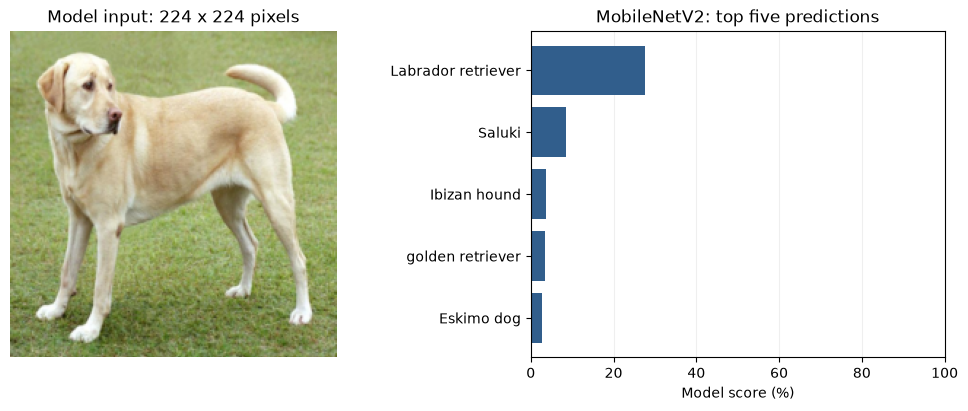

In [7]:
checks["Plot generation"] = False
labels = [label.replace("_", " ") for _, label, _ in top_predictions]
scores = [float(score) * 100 for _, _, score in top_predictions]

figure, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].imshow(image_224)
axes[0].set_title("Model input: 224 x 224 pixels")
axes[0].axis("off")
axes[1].barh(labels[::-1], scores[::-1], color="#315E8C")
axes[1].set_xlim(0, 100)
axes[1].set_xlabel("Model score (%)")
axes[1].set_title("MobileNetV2: top five predictions")
axes[1].grid(axis="x", alpha=0.2)
axes[1].set_axisbelow(True)
display(figure)
plt.close(figure)
checks["Plot generation"] = True

## 7. Record the result

This summary reports success only after all checks above have completed. Save this
notebook with its outputs and share the summary, or share the first error if a check fails.

In [8]:
required_checks = (
    "Environment and imports", "Dependency consistency", "GPU computation",
    "Image preparation", "Pretrained inference", "Plot generation",
)
for check in required_checks:
    print(f"{'PASS' if checks.get(check) else 'INCOMPLETE'}: {check}")
if not all(checks.get(check) for check in required_checks):
    raise RuntimeError("Verification is incomplete. Review the first failed cell.")

print("\nVERIFICATION PASSED")
print("Completed:", datetime.now().astimezone().isoformat(timespec="seconds"))
print("Python executable:", sys.executable)
print("Python version:", platform.python_version())
print("TensorFlow:", tf.__version__)
print("GPU:", gpu_name)
print("Top prediction:", labels[0])
print("Top model score:", f"{scores[0]:.2f}%")
print("Supplemental notebook complete; the official course notebook remains to be located.")

PASS: Environment and imports
PASS: Dependency consistency
PASS: GPU computation
PASS: Image preparation
PASS: Pretrained inference
PASS: Plot generation

VERIFICATION PASSED
Completed: 2026-09-03T16:10:49-05:00
Python executable: /home/aaron/projects/mipds/mipds_env/bin/python
Python version: 3.12.3
TensorFlow: 2.20.0
GPU: NVIDIA GeForce RTX 4060 Ti
Top prediction: Labrador retriever
Top model score: 27.52%
Supplemental notebook complete; the official course notebook remains to be located.


### References and scope

- [TensorFlow MobileNetV2 API](https://www.tensorflow.org/api_docs/python/tf/keras/applications/MobileNetV2): pretrained weights and required preprocessing.
- [TensorFlow sample-image tutorial](https://www.tensorflow.org/tutorials/generative/adversarial_fgsm): Labrador image and example ImageNet inference. This notebook uses the original image only.
- [VS Code notebook guide](https://code.visualstudio.com/docs/datascience/jupyter-notebooks): kernel selection, running cells, and saving output.

A passing result verifies this environment and example inference pipeline. It does
not establish training performance or model accuracy on exercise videos. Keep this
supplemental notebook distinct from any official notebook your instructor provides.